<a href="https://colab.research.google.com/github/Vandana-kannan/Cat-Dog-Image-Classification-CNN/blob/main/cat_dog_CNN_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub
path = kagglehub.dataset_download("andrewtoh78/cats-and-dogs-dataset")

100%|██████████| 86.7M/86.7M [00:00<00:00, 94.8MB/s]

Extracting files...


In [2]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import os
import tensorflow as tf
from tensorflow import keras


In [4]:
import os

print(os.listdir(path))


['cats_and_dogs_small']


In [5]:
for root, dirs, files in os.walk(path):
    print(root, "Number of images:", len(files))

/root/.cache/kagglehub/datasets/andrewtoh78/cats-and-dogs-dataset/versions/1 Number of images: 0
/root/.cache/kagglehub/datasets/andrewtoh78/cats-and-dogs-dataset/versions/1/cats_and_dogs_small Number of images: 0
/root/.cache/kagglehub/datasets/andrewtoh78/cats-and-dogs-dataset/versions/1/cats_and_dogs_small/train Number of images: 0
/root/.cache/kagglehub/datasets/andrewtoh78/cats-and-dogs-dataset/versions/1/cats_and_dogs_small/train/dogs Number of images: 1000
/root/.cache/kagglehub/datasets/andrewtoh78/cats-and-dogs-dataset/versions/1/cats_and_dogs_small/train/cats Number of images: 1000
/root/.cache/kagglehub/datasets/andrewtoh78/cats-and-dogs-dataset/versions/1/cats_and_dogs_small/validation Number of images: 0
/root/.cache/kagglehub/datasets/andrewtoh78/cats-and-dogs-dataset/versions/1/cats_and_dogs_small/validation/dogs Number of images: 500
/root/.cache/kagglehub/datasets/andrewtoh78/cats-and-dogs-dataset/versions/1/cats_and_dogs_small/validation/cats Number of images: 500
/ro

In [6]:
train_dir = r'/root/.cache/kagglehub/datasets/andrewtoh78/cats-and-dogs-dataset/versions/1/cats_and_dogs_small/train'

validation_dir = r'/root/.cache/kagglehub/datasets/andrewtoh78/cats-and-dogs-dataset/versions/1/cats_and_dogs_small/validation'

test_dir = r'/root/.cache/kagglehub/datasets/andrewtoh78/cats-and-dogs-dataset/versions/1/cats_and_dogs_small/test'

In [7]:
import os

print(os.path.exists(train_dir))
print(os.path.exists(validation_dir))
print(os.path.exists(test_dir))

True
True
True


In [8]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [9]:
train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)


In [10]:
train_generator= train_datagen.flow_from_directory(
    train_dir,
    batch_size=20,
    target_size=(150,150),
    class_mode="binary"
)

Found 2000 images belonging to 2 classes.


In [11]:
validation_generator= test_datagen.flow_from_directory(
    test_dir,
    batch_size=20,
    target_size=(150,150),
    class_mode="binary"
)

Found 1000 images belonging to 2 classes.


In [13]:
from tensorflow.keras import layers
from tensorflow.keras import models

In [15]:
model=models.Sequential()
model.add(layers.Conv2D(32,(3,3),activation='relu',input_shape=(150,150,3)))
model.add(layers.MaxPooling2D(2,2))
model.add(layers.Conv2D(64,(3,3,),activation="relu"))
model.add(layers.MaxPooling2D(2,2))
model.add(layers.Conv2D(128,(3,3),activation="relu"))
model.add(layers.MaxPooling2D(2,2))
model.add(layers.Conv2D(128,(3,3),activation="relu"))
model.add(layers.MaxPooling2D(2,2))
model.add(layers.Flatten())
model.add(layers.Dense(512,activation="relu"))
model.add(layers.Dense(1,activation="sigmoid"))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [16]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,453,121 (13.17 MB)

 Trainable params: 3,453,121 (13.17 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
from tensorflow.keras import optimizers

In [21]:
model.compile(
    loss="binary_crossentropy",
    optimizer=optimizers.RMSprop(learning_rate=1e-4),
    metrics=['acc']
    )

In [23]:
history=model.fit(
    train_generator,
    steps_per_epoch=100,
    epochs=20,
    validation_data=validation_generator,
    validation_steps=50
)

Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 154s 2s/step - acc: 0.5415 - loss: 0.6909 - val_acc: 0.5860 - val_loss: 0.6869
Epoch 2/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 199s 2s/step - acc: 0.5715 - loss: 0.6813 - val_acc: 0.5710 - val_loss: 0.6739
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 202s 2s/step - acc: 0.6015 - loss: 0.6627 - val_acc: 0.5280 - val_loss: 0.7001
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 163s 2s/step - acc: 0.6415 - loss: 0.6347 - val_acc: 0.5810 - val_loss: 0.6693
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 170s 2s/step - acc: 0.6715 - loss: 0.6056 - val_acc: 0.5800 - val_loss: 0.6675
Epoch 6/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 157s 2s/step - acc: 0.7085 - loss: 0.5702 - val_acc: 0.6770 - val_loss: 0.6029
Epoch 7/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 150s 2s/step - acc: 0.7075 - loss: 0.5487 - val_acc: 0.6830 - val_loss: 0.5891
Epoch 8/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 152s 2s/step - acc: 0.7315 - loss: 0.5269 - val_acc: 0.6910 - val_loss: 0.5776
Epoch 9/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 152s 2s/

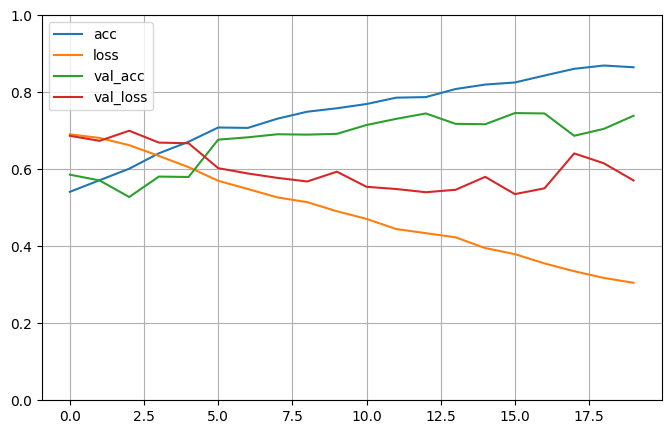

In [26]:
pd.DataFrame(history.history).plot(figsize=(8,5))
plt.grid(True)
plt.gca().set_ylim(0,1)
plt.show()

In [27]:
model.save("cat_dog_model.h5")

In [ ]:
from tensorflow.keras import backend as k
k.clear_session()
